# FIFA World Cup 2026 — Objective 2: Linear Regression (Updated CSV Folder Version)
**Data wrangling • eight predictors per model • scatterplots • multiple train/test splits • diagnostics**

This notebook uses the consolidated source data from **Mel's Code and Testing**, alongside the three standardised FIFA2026 analysis/result CSVs. Nine CSV files live in the **single `CSV_Files/` folder** beside the notebook; original ZIPs are **not needed**.

- **2.1:** 104 World Cup 2026 matches; target = Home − Away goals, using 8 predictors.
- **2.2:** 208 team-match rows; target = team goals scored, using 8 predictors.
- Both teams from one match stay together when testing 2.2. The main test is chronological 80/20.
- Run **Kernel → Restart & Run All**. The notebook **reads the renamed analysis CSVs for input validation** and regenerates them with current outputs; plots are saved to `plots/`.

**Source/academic limitations:** The supplied `Experience.csv` reports World Cup matches per player after 2026 fixtures; **Objective 2.2 X3 is a post-tournament proxy** unless a correctly sourced `CSV_Files/pre2026_squad_experience.csv` is supplied. The model is therefore **exploratory and not submission-ready** without that replacement. Market-value snapshot dates are undocumented. Calculated Elo is an Elo-style approximation, not certified external Elo rankings.

**Data organisation:** The original 10 Testing CSVs were consolidated into three CSVs: 104-match inputs, 208-team-match inputs, and a long-form archive for older Testing calculations (not used in model training). The three final assessment CSVs remain separate.


## 0. Packages and reproducibility

This is basic multiple linear regression, as requested. We keep the same columns for each split, fit imputation **on training rows only**, and use a fixed random seed for repeatability.

In [1]:
from pathlib import Path
import re, warnings
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

SEED = 42
ROOT = Path.cwd()
DATA_DIR = ROOT / 'CSV_Files'       # All CSV inputs and the 3 CSV outputs
OUT = ROOT / 'plots'             # Only chart images go in this separate folder
if not DATA_DIR.is_dir():
    raise FileNotFoundError('CSV_Files folder missing: extract the entire supplied ZIP first.')
OUT.mkdir(exist_ok=True)
ALLOW_EXPLORATORY_POST2026_EXPERIENCE = True
plt.rcParams.update({'figure.figsize': (7, 4.5), 'font.size': 10})
print('Working directory:', ROOT)
print('CSV folder:', DATA_DIR)


Working directory: /mnt/data/FIFA2026_Compact_Project
CSV folder: /mnt/data/FIFA2026_Compact_Project/CSV_Files


## 1. Load the CSVs and check the prepared filenames

All CSV files are directly in `CSV_Files/`. The **consolidated Mel's Code and Testing source datasets** are used to reconstruct pre-match predictors. The **three renamed analysis/result files** are also read and checked as provided snapshots; Section 13 regenerates them to keep results consistent when you re-run the notebook. No ZIP inputs are needed.


In [2]:
def read_csv(name, encoding='utf-8'):
    path = DATA_DIR / name
    if not path.is_file():
        raise FileNotFoundError(f'Required file not found: {path}')
    return pd.read_csv(path, encoding=encoding)

# Named, prepared datasets supplied with the package.
OUTPUT_21 = 'FIFA2026_Objective2_1_Goal_Difference_104_Matches.csv'
OUTPUT_22 = 'FIFA2026_Objective2_2_Goals_Scored_208_TeamMatches.csv'
OUTPUT_METRICS = 'FIFA2026_Objective2_Model_Evaluation_and_Diagnostics.csv'
existing21 = read_csv(OUTPUT_21)
existing22 = read_csv(OUTPUT_22)
existing_metrics = read_csv(OUTPUT_METRICS)
assert len(existing21) == 104 and len(existing22) == 208
assert len(existing_metrics) == 152
print('Renamed CSV files loaded:', existing21.shape, existing22.shape, existing_metrics.shape)

# Original six source files (3 from Mel; 3 primary data files from Testing).
source_matches = read_csv('FIFA2026_Source_Match_Data_104.csv')
old21 = source_matches[[c for c in source_matches.columns if not c.startswith('FBref_')]].copy()
raw = source_matches[[c for c in source_matches.columns if c.startswith('FBref_')]].copy()
raw.columns = raw.columns.str.removeprefix('FBref_').str.replace('_',' ', regex=False)
old22 = read_csv('FIFA2026_Source_Team_Match_Data_208.csv')
history = read_csv('International_results.csv')
age = read_csv('Age.csv', encoding='cp1252')
experience = read_csv('Experience.csv', encoding='cp1252')

print('Raw FBref matches:', raw.shape, '| Prior 2.1:', old21.shape, '| Prior 2.2:', old22.shape)
print('International results:', history.shape, '| Squad age/value:', age.shape,
      '| Squad experience:', experience.shape)
assert len(raw) == len(old21) == 104, 'Objective 2.1 must have 104 matches.'
assert len(old22) == 208, 'Objective 2.2 must have 208 team-match records.'
assert old21['Match_ID'].is_unique
assert old22[['Match_ID', 'Team']].duplicated().sum() == 0
assert old22.groupby('Match_ID').size().eq(2).all(), 'Each match must have both teams.'
display(old21[['Match_ID', 'Date', 'Team_A', 'Team_B', 'Y_Actual_Goal_Difference']].head())


Renamed CSV files loaded: (104, 17) (208, 18) (152, 8)
Raw FBref matches: (104, 13) | Prior 2.1: (104, 15) | Prior 2.2: (208, 12)
International results: (49945, 9) | Squad age/value: (48, 8) | Squad experience: (48, 11)


,Match_ID,Date,Team_A,Team_B,Y_Actual_Goal_Difference
0,1,2026-06-11,Mexico,South Africa,2
1,2,2026-06-11,South Korea,Czechia,1
2,3,2026-06-12,Canada,Bosnia and Herzegovina,0
3,4,2026-06-12,United States,Paraguay,3
4,5,2026-06-13,Qatar,Switzerland,0


## 2. Clean team names, dates, score columns and value formats

Names have to match across FBref, international historical results, team market-value table, and squad experience. Market values are parsed from strings like `€1.46bn`, `€63.30m`. All market values are converted to **millions of euros** before calculating log differences.

In [3]:
TEAM_MAP = {
    'DR Congo': 'DR Congo',
    'Democratic Republic of the Congo': 'DR Congo',
    'Congo DR': 'DR Congo',
    'Bosnia-Herzegovina': 'Bosnia and Herzegovina',
    'Bosnia–Herz': 'Bosnia and Herzegovina',
    'Turkiye': 'Turkey', 'Türkiye': 'Turkey',
    'Czech Republic': 'Czechia',
    'Korea Republic': 'South Korea',
    'Cabo Verde': 'Cape Verde',
    "Côte d'Ivoire": 'Ivory Coast',
    'USA': 'United States',
}
def clean_team(x):
    x = str(x).strip()
    return TEAM_MAP.get(x, x)

def market_millions(value):
    s = str(value).lower().replace('€','').replace(',','').strip()
    m = re.search(r'([0-9]+(?:\.[0-9]+)?)\s*(bn|b|m|million|k)?', s)
    if m is None:
        return np.nan
    v = float(m.group(1)); unit = m.group(2)
    return v * (1000 if unit in ('bn','b') else (0.001 if unit=='k' else 1))

for c in ['Team_A','Team_B']:
    old21[c] = old21[c].map(clean_team)
for c in ['Team','Opponent']:
    old22[c] = old22[c].map(clean_team)
for c in ['home_team','away_team']:
    history[c] = history[c].map(clean_team)
for table in (age, experience):
    table['Club'] = table['Club'].map(clean_team)

old21['Date'] = pd.to_datetime(old21['Date'], errors='raise').dt.normalize()
old22['Date'] = pd.to_datetime(old22['Date'], errors='raise').dt.normalize()
history['date'] = pd.to_datetime(history['date'], format='mixed', dayfirst=True, errors='raise').dt.normalize()
for c in ['home_score', 'away_score']:
    history[c] = pd.to_numeric(history[c], errors='raise')
age['MarketValue_EUR_M'] = age['Market Value'].map(market_millions)
age['Avg_Age'] = pd.to_numeric(age['ø-Age'], errors='coerce')
age['WC_Participations'] = pd.to_numeric(age['WC particip.'], errors='coerce')
experience['MostExp_Pre2026'] = pd.to_numeric(experience['pre 2026'], errors='coerce')
experience['SquadExp_AsSupplied_Post2026'] = pd.to_numeric(
    experience['World Cup matches per player'], errors='coerce')
assert age['Club'].is_unique and experience['Club'].is_unique
assert age['MarketValue_EUR_M'].gt(0).all(), 'Market values must be positive.'
assert (experience['MostExp_Pre2026'] >= 0).all()

print('Market value range (EUR million):',
      age.MarketValue_EUR_M.min(), 'to', age.MarketValue_EUR_M.max())
print('Date range of matches:', old21.Date.min().date(), 'to', old21.Date.max().date())
print('Historical file end date:', history.date.max().date())
print('Unmatched squad-age team names:', sorted((set(old21.Team_A)|set(old21.Team_B))-set(age.Club)))
print('Unmatched experience team names:', sorted((set(old21.Team_A)|set(old21.Team_B))-set(experience.Club)))

Market value range (EUR million): 16.8 to 1460.0
Date range of matches: 2026-06-11 to 2026-07-19
Historical file end date: 2026-10-06
Unmatched squad-age team names: []
Unmatched experience team names: []


## 3. Build strictly pre-match international form and Elo-like ratings

For each game, international-history features are computed **only from matches whose date is strictly earlier** than its date. Thus even if a team plays twice on the same date, neither same-day result leaks into the earlier prediction.

**Elo specification (student-generated):** start each team at 1500 on 1 January 2016; update by `20 × (actual match outcome − expected result)` on completed internationals, with **no home advantage**. Ratings are captured before each World Cup match date. This is a transparent, reproducible *Elo-style approximation*, not verified third-party ratings. Penalty shootouts are treated as drawn scores where the supplied result records a draw.

In [4]:
# Long format: 1 historical match becomes 2 team records.
h1 = history[['date','home_team','away_team','home_score','away_score']].rename(
    columns={'home_team':'team','away_team':'opponent','home_score':'GF','away_score':'GA'})
h2 = history[['date','home_team','away_team','home_score','away_score']].rename(
    columns={'away_team':'team','home_team':'opponent','away_score':'GF','home_score':'GA'})
long_hist = pd.concat([h1,h2], ignore_index=True)
long_hist['Win'] = (long_hist.GF > long_hist.GA).astype(float)
long_hist['Unbeaten'] = (long_hist.GF >= long_hist.GA).astype(float)
long_hist = long_hist.sort_values('date', kind='mergesort')
hist_by_team = {team: group for team, group in long_hist.groupby('team', sort=False)}

def previous_matches(team, match_date, n=None):
    group = hist_by_team.get(team)
    if group is None:
        return long_hist.iloc[0:0]
    prior = group[group['date'] < match_date]
    return prior if n is None else prior.tail(n)

def international_form(team, match_date):
    last7 = previous_matches(team, match_date, 7)
    last1 = previous_matches(team, match_date, 1)
    return {
        'win7': last7.Win.mean(),
        'conceded7': last7.GA.mean(),
        'unbeaten7': last7.Unbeaten.mean(),
        'days_since_last': (match_date-last1.date.iloc[-1]).days if len(last1) else np.nan,
        'prior7_games': len(last7),
    }

# Treat all games on the same date as a batch to avoid same-day outcome leakage.
elo_hist = history.loc[history.date >= pd.Timestamp('2016-01-01')].sort_values(
    'date',kind='mergesort')
ratings = defaultdict(lambda: 1500.0)
elo_snapshots = {}
needed_dates = set(old21.Date)
for day, block in elo_hist.groupby('date', sort=True):
    if day in needed_dates:
        elo_snapshots[day] = dict(ratings) # copy BEFORE playing this day's games
    changes = defaultdict(float)
    for row in block.itertuples(index=False):
        a,b = row.home_team,row.away_team
        ra,rb = ratings[a],ratings[b]
        p_a = 1/(1 + 10**((rb-ra)/400))
        s_a = 1 if row.home_score > row.away_score else (.5 if row.home_score == row.away_score else 0)
        change = 20*(s_a-p_a)
        changes[a] += change; changes[b] -= change
    for team,delta in changes.items():
        ratings[team] += delta
assert len(elo_snapshots) == len(needed_dates), 'Some World Cup dates missing in Elo history.'

def prematch_elo(team, day):
    return elo_snapshots[day].get(team, 1500.0)

print('Matches with no previous 7 international games:',
      sum(len(previous_matches(t, d, 7)) == 0 for d,t in zip(old21.Date,old21.Team_A)))
print('Elo snapshots:', len(elo_snapshots))

Matches with no previous 7 international games: 0
Elo snapshots: 34


## 4. Objective 2.1 — all eight variables (104 match rows)

1. **X1** Past 7 international win-rate difference (Home − Away, MH)
2. **X2** Past 7 international average goals-conceded difference (Home − Away, MH)
3. **X3** World Cup participation count difference (Home − Away, MH)
4. **X4** Most experienced player's **pre-2026** World Cup match count difference (Home − Away, MH)
5. **X5** Previous **2026 tournament** average goal-difference difference (Home − Away, N)
6. **X6** Previous **2026 tournament** win-rate difference (Home − Away, N)
7. **X7** Log team market-value difference (Home − Away, MA)
8. **X8** Calculated pre-match Elo difference (Home − Away, MA)

**Note:** X1 and X6 both measure wins but use *different look-back windows*. The brief permits both; we check their correlation and VIF later rather than silently removing a chosen variable. X5/X6 are undefined for opening matches and are imputed **inside the training pipeline only**, preserving all 104 match rows.

In [5]:
AGE = age.set_index('Club')
EXP = experience.set_index('Club')

f21 = old21[['Match_ID','Date','Round','Team_A','Team_B',
             'X1_PreMatch_GD_Difference','X2_PreMatch_Win_Rate_Difference',
             'Y_Actual_Goal_Difference']].copy()
forms21 = []
for row in f21.itertuples(index=False):
    a, b, d = row.Team_A,row.Team_B,row.Date
    fa,fb = international_form(a,d),international_form(b,d)
    forms21.append({
        'X1_Past7_WinRate_Diff': fa['win7']-fb['win7'],
        'X2_Past7_GoalsConceded_Diff': fa['conceded7']-fb['conceded7'],
        'X3_WC_Participations_Diff': AGE.loc[a,'WC_Participations']-AGE.loc[b,'WC_Participations'],
        'X4_MostExpPlayer_Pre2026_Diff': EXP.loc[a,'MostExp_Pre2026']-EXP.loc[b,'MostExp_Pre2026'],
        'X7_Log_MarketValue_Diff': np.log(AGE.loc[a,'MarketValue_EUR_M'])-np.log(AGE.loc[b,'MarketValue_EUR_M']),
        'X8_PreMatch_Computed_Elo_Diff': prematch_elo(a,d)-prematch_elo(b,d),
    })
f21 = pd.concat([f21.reset_index(drop=True),pd.DataFrame(forms21)],axis=1)
f21 = f21.rename(columns={
    'X1_PreMatch_GD_Difference':'X5_Prior_WC_GoalDifference_Diff',
    'X2_PreMatch_Win_Rate_Difference':'X6_Prior_WC_WinRate_Diff',
    'Y_Actual_Goal_Difference':'Y_GoalDifference'})
FEATURE21 = [
    'X1_Past7_WinRate_Diff','X2_Past7_GoalsConceded_Diff',
    'X3_WC_Participations_Diff','X4_MostExpPlayer_Pre2026_Diff',
    'X5_Prior_WC_GoalDifference_Diff','X6_Prior_WC_WinRate_Diff',
    'X7_Log_MarketValue_Diff','X8_PreMatch_Computed_Elo_Diff']
assert len(FEATURE21)==8 and len(f21)==104
assert f21['Y_GoalDifference'].notna().all()
print('2.1: 104 rows; missing predictors (cold-start is expected for X5/X6):')
display(f21[FEATURE21].isna().sum().rename('Missing rows').to_frame())
# Individual CSV export consolidated in section 13.
display(f21[['Match_ID','Team_A','Team_B']+FEATURE21].head(3))

2.1: 104 rows; missing predictors (cold-start is expected for X5/X6):


,Missing rows
X1_Past7_WinRate_Diff,0
X2_Past7_GoalsConceded_Diff,0
X3_WC_Participations_Diff,0
X4_MostExpPlayer_Pre2026_Diff,0
X5_Prior_WC_GoalDifference_Diff,24
X6_Prior_WC_WinRate_Diff,24
X7_Log_MarketValue_Diff,0
X8_PreMatch_Computed_Elo_Diff,0


,Match_ID,Team_A,Team_B,X1_Past7_WinRate_Diff,X2_Past7_GoalsConceded_Diff,X3_WC_Participations_Diff,X4_MostExpPlayer_Pre2026_Diff,X5_Prior_WC_GoalDifference_Diff,X6_Prior_WC_WinRate_Diff,X7_Log_MarketValue_Diff,X8_PreMatch_Computed_Elo_Diff
0,1,Mexico,South Africa,0.428571,-0.857143,14,7,NaN,NaN,1.586778,101.816114
1,2,South Korea,Czechia,0.142857,-0.428571,10,10,NaN,NaN,-0.291737,102.638104
2,3,Canada,Bosnia and Herzegovina,0.000000,-0.428571,1,1,NaN,NaN,-0.132395,188.386646


## 5. Objective 2.2 — all eight variables (208 team-match rows)

1. **X1** Log market-value difference (Team − Opponent, MA)
2. **X2** Calculated pre-match Elo difference (Team − Opponent, MA)
3. **X3** Squad average World Cup matches per player difference (Team − Opponent, MA) — **requires verified pre-2026 squad data**
4. **X4** Pre-match unbeaten rate across preceding 7 internationals (**team rate**, MA)
5. **X5** Team pre-match average goals scored in the 2026 tournament (N)
6. **X6** Opponent pre-match average goals conceded in the 2026 tournament (N)
7. **X7** Team average squad age (new)
8. **X8** Days since team's previous international match (new)

The supplied `Experience.csv` has `World Cup matches per player`, but values are reported **after 2026 games**. No valid subtraction of 2026 squad appearances is possible using the supplied aggregated table alone. We accept a verified external *pre-2026* table if provided. Otherwise X3 is the supplied post-2026 number and must be treated as **exploratory leakage-risk data**, even though it is attached before the actual regression.

In [6]:
# Optional strictly pre-tournament source: exact data columns below, one row per 2026 squad.
# Source should be documented with a date showing it predates the team's first 2026 WC match.
pre_wc_file = DATA_DIR / 'pre2026_squad_experience.csv'
if pre_wc_file.exists():
    pre_exp = pd.read_csv(pre_wc_file)
    required = {'Team','Pre2026_Squad_Avg_WC_Matches_Per_Player'}
    if not required.issubset(pre_exp.columns):
        raise ValueError(f'{pre_wc_file.name} must contain columns {required}')
    pre_exp['Team'] = pre_exp.Team.map(clean_team)
    pre_exp = pre_exp.set_index('Team')
    if not set(AGE.index).issubset(pre_exp.index):
        raise ValueError('Verified pre-2026 squad experience is missing one or more teams.')
    verified_pre2026_experience = True
    team_experience = pre_exp['Pre2026_Squad_Avg_WC_Matches_Per_Player']
    print('OK: Using externally supplied PRE-2026 squad-experience values.')
else:
    verified_pre2026_experience = False
    if not ALLOW_EXPLORATORY_POST2026_EXPERIENCE:
        raise ValueError('Pre-2026 squad experience not supplied. Cannot fit a compliant 8-variable 2.2 model.')
    team_experience = EXP['SquadExp_AsSupplied_Post2026']
    warnings.warn('LEAKAGE RISK: Objective 2.2 X3 uses a post-2026 squad experience proxy. '
                  'Results are DEMONSTRATION ONLY until a valid pre-2026 CSV is provided.')

f22 = old22[['TeamMatch_ID','Match_ID','Date','Round','Team','Opponent',
             'X1_Team_PreMatch_Avg_Goals_Scored','X2_Opponent_PreMatch_Avg_Goals_Conceded',
             'Y_Actual_Team_Goals']].copy()
forms22=[]
for row in f22.itertuples(index=False):
    t,o,d = row.Team,row.Opponent,row.Date
    ft = international_form(t,d)
    forms22.append({
        'X1_Log_MarketValue_Diff': np.log(AGE.loc[t,'MarketValue_EUR_M'])-np.log(AGE.loc[o,'MarketValue_EUR_M']),
        'X2_PreMatch_Computed_Elo_Diff': prematch_elo(t,d)-prematch_elo(o,d),
        'X3_Squad_Avg_WC_MatchesPP_Diff': float(team_experience[t])-float(team_experience[o]),
        'X4_Past7_UnbeatenRate_Team': ft['unbeaten7'],
        'X7_Avg_SquadAge_Team': AGE.loc[t,'Avg_Age'],
        'X8_DaysSincePrevInternational_Team': ft['days_since_last'],
    })
f22 = pd.concat([f22.reset_index(drop=True),pd.DataFrame(forms22)],axis=1)
f22=f22.rename(columns={
    'X1_Team_PreMatch_Avg_Goals_Scored':'X5_Prior_WC_Team_AvgGoals',
    'X2_Opponent_PreMatch_Avg_Goals_Conceded':'X6_Prior_WC_Opp_AvgConceded',
    'Y_Actual_Team_Goals':'Y_TeamGoals'})
FEATURE22 = [
    'X1_Log_MarketValue_Diff','X2_PreMatch_Computed_Elo_Diff',
    'X3_Squad_Avg_WC_MatchesPP_Diff','X4_Past7_UnbeatenRate_Team',
    'X5_Prior_WC_Team_AvgGoals','X6_Prior_WC_Opp_AvgConceded',
    'X7_Avg_SquadAge_Team','X8_DaysSincePrevInternational_Team']
assert len(FEATURE22)==8 and len(f22)==208
assert f22['Y_TeamGoals'].notna().all()
assert f22.groupby('Match_ID').size().eq(2).all()
print('2.2: 208 rows; missing predictors:')
display(f22[FEATURE22].isna().sum().rename('Missing rows').to_frame())
print('Submission-grade X3?', verified_pre2026_experience)
if not verified_pre2026_experience:
    display(Markdown('> **WARNING: All 2.2 model results below are provisional. '
                     'Replace X3 with documented pre-2026 squad data before submitting.**'))
# Individual CSV export consolidated in section 13.
display(f22[['Match_ID','Team','Opponent']+FEATURE22].head(3))

2.2: 208 rows; missing predictors:


/tmp/ipykernel_2993/2243194313.py:21: UserWarning: LEAKAGE RISK: Objective 2.2 X3 uses a post-2026 squad experience proxy. Results are DEMONSTRATION ONLY until a valid pre-2026 CSV is provided.
  warnings.warn('LEAKAGE RISK: Objective 2.2 X3 uses a post-2026 squad experience proxy. '


,Missing rows
X1_Log_MarketValue_Diff,0
X2_PreMatch_Computed_Elo_Diff,0
X3_Squad_Avg_WC_MatchesPP_Diff,0
X4_Past7_UnbeatenRate_Team,0
X5_Prior_WC_Team_AvgGoals,48
X6_Prior_WC_Opp_AvgConceded,48
X7_Avg_SquadAge_Team,0
X8_DaysSincePrevInternational_Team,0


Submission-grade X3? False


> **WARNING: All 2.2 model results below are provisional. Replace X3 with documented pre-2026 squad data before submitting.**

,Match_ID,Team,Opponent,X1_Log_MarketValue_Diff,X2_PreMatch_Computed_Elo_Diff,X3_Squad_Avg_WC_MatchesPP_Diff,X4_Past7_UnbeatenRate_Team,X5_Prior_WC_Team_AvgGoals,X6_Prior_WC_Opp_AvgConceded,X7_Avg_SquadAge_Team,X8_DaysSincePrevInternational_Team
0,1,Mexico,South Africa,1.586778,101.816114,1.50,1.000000,NaN,NaN,25.7,7
1,1,South Africa,Mexico,-1.586778,-101.816114,-1.50,0.571429,NaN,NaN,27.2,5
2,2,South Korea,Czechia,-0.291737,102.638104,1.88,0.714286,NaN,NaN,28.5,8


## 6. Data-quality and pre-match checks

The 208-row table must contain both teams for every match, with complementary scores. There must be no duplicate match IDs or missing targets. We additionally check that the recorded targets align between 2.1 and 2.2. **Do not replace a mismatched score silently.**

In [7]:
score21=f21.set_index('Match_ID')['Y_GoalDifference'].sort_index()
score22=f22.pivot(index='Match_ID',columns='Team',values='Y_TeamGoals')
# Match orientation is given by Team_A (Home) vs Team_B (Away).
check=[]
for row in f21[['Match_ID','Team_A','Team_B','Y_GoalDifference']].itertuples(index=False):
    goals_a=score22.loc[row.Match_ID, row.Team_A]
    goals_b=score22.loc[row.Match_ID, row.Team_B]
    check.append((goals_a-goals_b)==row.Y_GoalDifference)
assert all(check), '2.1 goal differences do not agree with corresponding 2.2 scores.'
assert f21[FEATURE21].select_dtypes(include='number').shape[1]==8
assert f22[FEATURE22].select_dtypes(include='number').shape[1]==8
for obj,df,cols in [('2.1',f21,FEATURE21),('2.2',f22,FEATURE22)]:
    print(f'{obj}: rows={len(df)}, 8 feature columns={len(cols)}, numeric infinities=',
          np.isinf(df[cols].to_numpy(dtype=float)).sum())
    if np.isinf(df[cols].to_numpy(dtype=float)).any():
        raise ValueError('Infinite feature value detected.')
    print('  duplicates=',df.duplicated().sum(),
          '| all-null features=', df[cols].isna().all().sum())
# 2.2 team/opp difference features should be equal and opposite within a match.
for col in FEATURE22[:3]:
    opposite = f22.groupby('Match_ID')[col].sum()
    assert np.allclose(opposite,0,atol=1e-8), f'Feature {col} not antisymmetric.'
print('PASS: outcomes align across 104 / 208 rows, and difference features have correct signs.')

2.1: rows=104, 8 feature columns=8, numeric infinities= 0
  duplicates= 0 | all-null features= 0
2.2: rows=208, 8 feature columns=8, numeric infinities= 0
  duplicates= 0 | all-null features= 0
PASS: outcomes align across 104 / 208 rows, and difference features have correct signs.


## 7. Descriptive statistics and correlation/scatterplot checks

Scatterplots help detect approximate linear relationships and outliers. Each panel includes a simple trend line, Pearson correlation (`r`), and observed case count. A near-zero `r` does **not** prove the variable is useless in a multivariable model. Plots and tables are saved into the output folder.


 Objective2_1 — predictor descriptions


,count,mean,std,min,25%,50%,75%,max
X1_Past7_WinRate_Diff,104.0,0.058,0.311,-1.000,-0.143,0.071,0.286,0.857
X2_Past7_GoalsConceded_Diff,104.0,-0.058,0.795,-2.000,-0.571,0.000,0.429,2.429
X3_WC_Participations_Diff,104.0,2.692,9.011,-19.000,-3.000,2.500,10.000,21.000
X4_MostExpPlayer_Pre2026_Diff,104.0,1.096,9.132,-26.000,-4.000,0.500,6.250,26.000
X5_Prior_WC_GoalDifference_Diff,80.0,0.315,2.108,-6.000,-0.750,0.708,1.500,5.000
X6_Prior_WC_WinRate_Diff,80.0,0.045,0.441,-1.000,0.000,0.000,0.271,1.000
X7_Log_MarketValue_Diff,104.0,0.335,1.765,-3.858,-0.829,0.499,1.399,4.465
X8_PreMatch_Computed_Elo_Diff,104.0,19.765,121.024,-235.183,-60.444,-1.630,115.339,257.908
Y_GoalDifference,104.0,0.481,2.024,-4.000,-1.000,0.000,2.000,6.000


Correlation with target (pairwise non-missing):


,Pearson r
X7_Log_MarketValue_Diff,0.676
X8_PreMatch_Computed_Elo_Diff,0.589
X3_WC_Participations_Diff,0.546
X1_Past7_WinRate_Diff,0.489
X4_MostExpPlayer_Pre2026_Diff,0.406
X2_Past7_GoalsConceded_Diff,-0.393
X5_Prior_WC_GoalDifference_Diff,0.371
X6_Prior_WC_WinRate_Diff,0.212


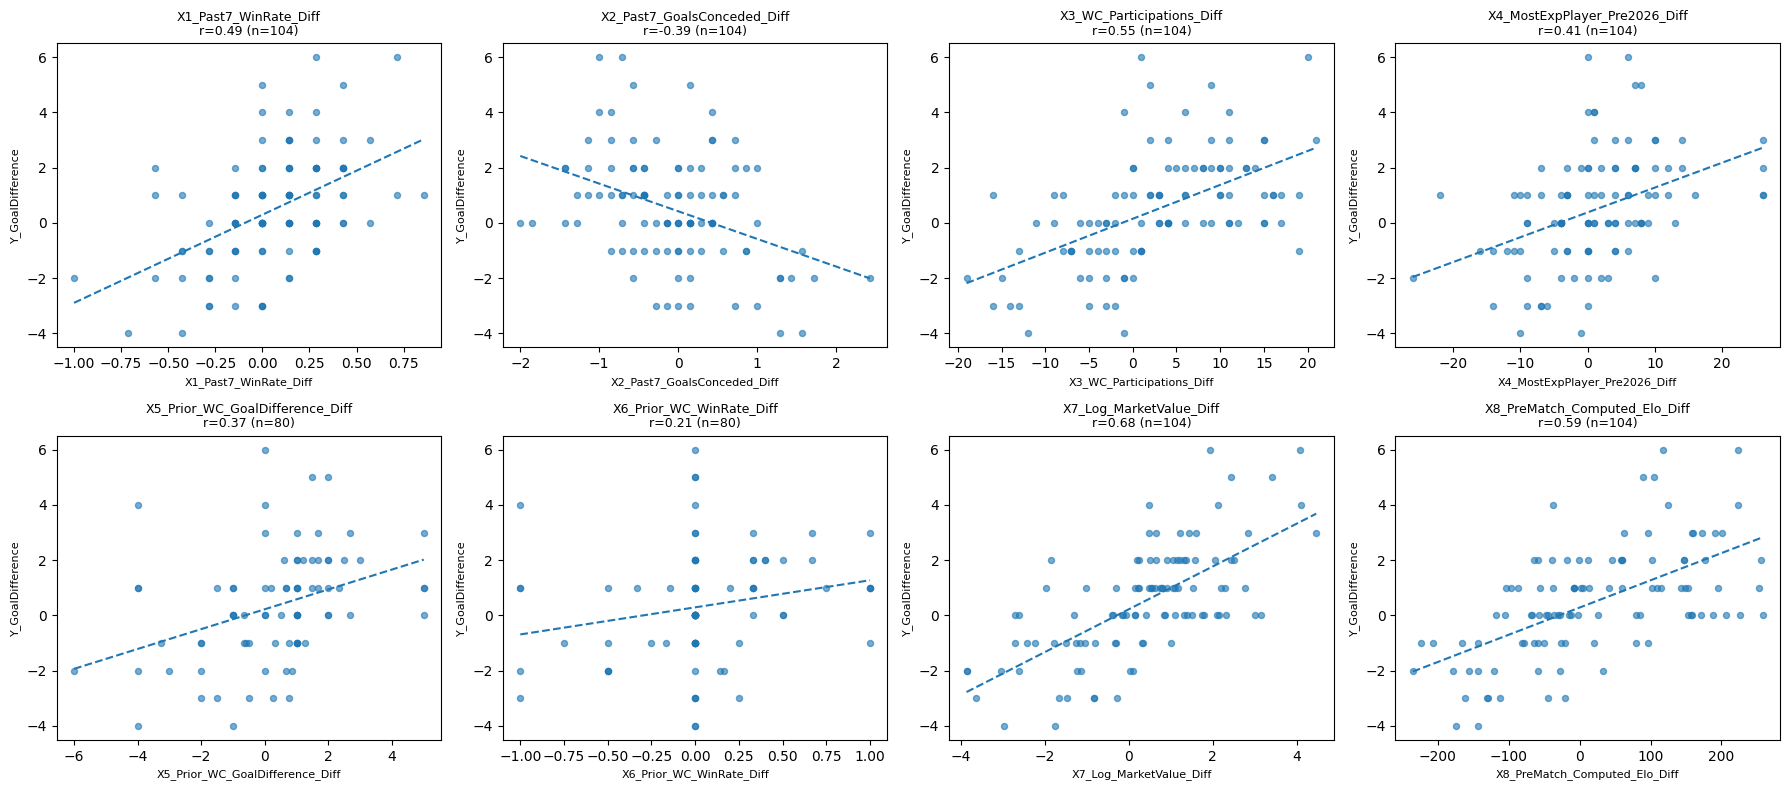


 Objective2_2 — predictor descriptions


,count,mean,std,min,25%,50%,75%,max
X1_Log_MarketValue_Diff,208.0,0.000,1.793,-4.465,-1.220,0.000,1.220,4.465
X2_PreMatch_Computed_Elo_Diff,208.0,0.000,122.346,-257.908,-90.981,0.000,90.981,257.908
X3_Squad_Avg_WC_MatchesPP_Diff,208.0,0.000,1.978,-4.830,-1.162,0.000,1.162,4.830
X4_Past7_UnbeatenRate_Team,208.0,0.771,0.203,0.286,0.571,0.857,1.000,1.000
X5_Prior_WC_Team_AvgGoals,160.0,1.728,1.106,0.000,1.000,1.708,2.333,7.000
X6_Prior_WC_Opp_AvgConceded,160.0,1.270,1.097,0.000,0.593,1.000,1.700,7.000
X7_Avg_SquadAge_Team,208.0,26.476,1.239,22.900,25.700,26.250,27.125,29.600
X8_DaysSincePrevInternational_Team,208.0,6.284,5.182,3.000,5.000,6.000,6.250,76.000
Y_TeamGoals,208.0,1.481,1.393,0.000,0.000,1.000,2.000,7.000


Correlation with target (pairwise non-missing):


,Pearson r
X1_Log_MarketValue_Diff,0.514
X2_PreMatch_Computed_Elo_Diff,0.449
X3_Squad_Avg_WC_MatchesPP_Diff,0.411
X4_Past7_UnbeatenRate_Team,0.247
X6_Prior_WC_Opp_AvgConceded,0.215
X7_Avg_SquadAge_Team,-0.171
X5_Prior_WC_Team_AvgGoals,0.111
X8_DaysSincePrevInternational_Team,-0.013


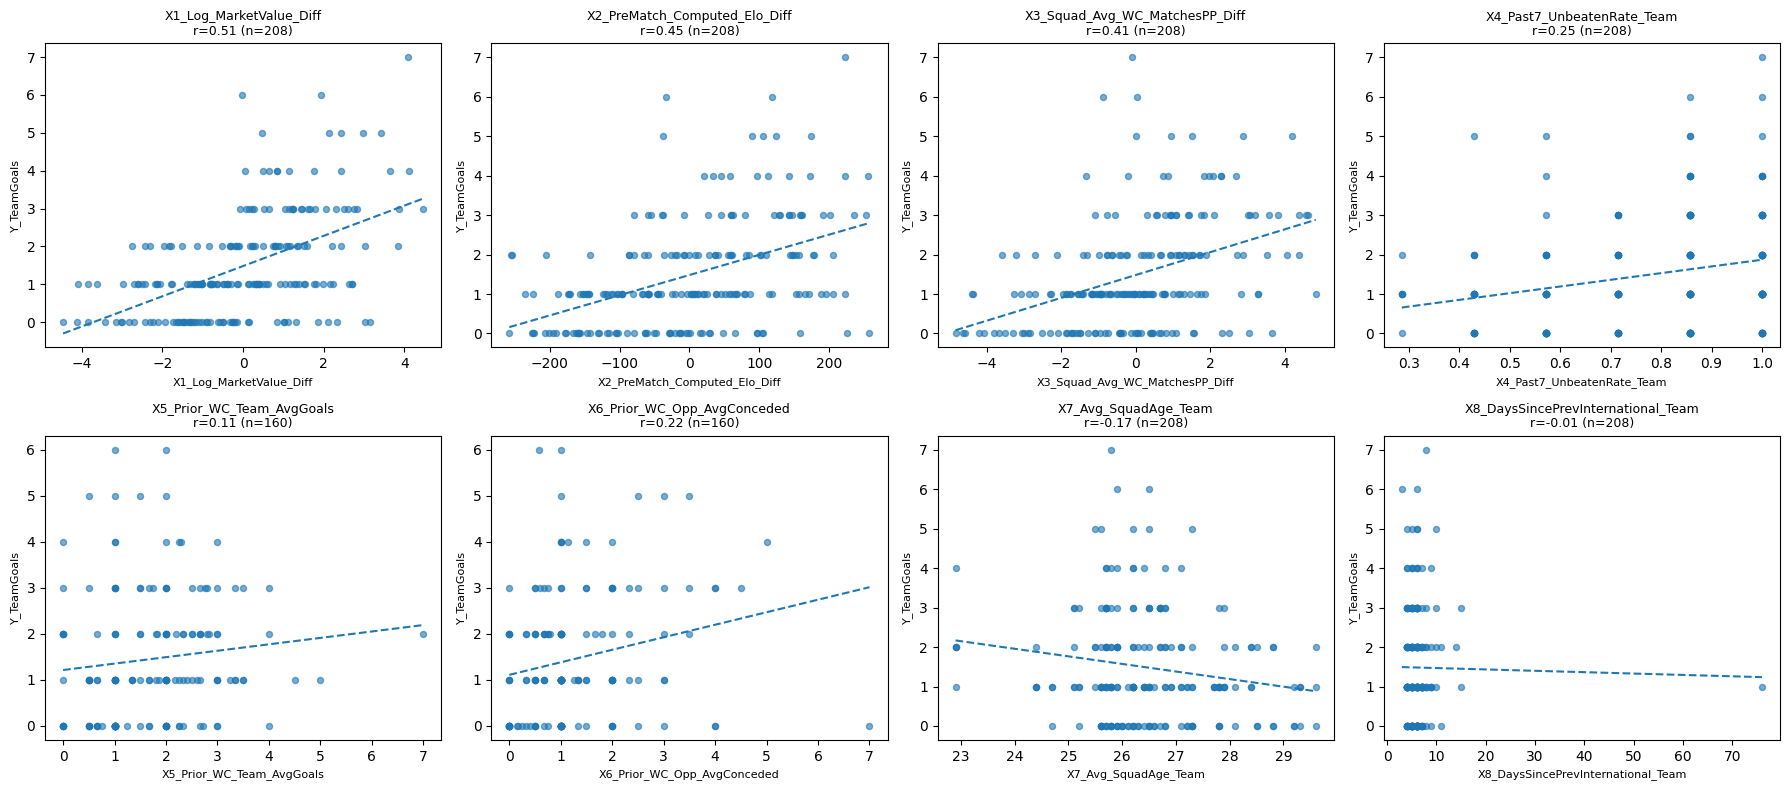

In [8]:
def descriptive_checks(df, cols, target, label):
    print('\n',label, '— predictor descriptions')
    display(df[cols + [target]].describe().T.round(3))
    print('Correlation with target (pairwise non-missing):')
    correlations=df[cols + [target]].corr(numeric_only=True)[target].drop(target)
    display(correlations.sort_values(key=np.abs,ascending=False).to_frame('Pearson r').round(3))
    fig,axes=plt.subplots(2,4,figsize=(18,8))
    for ax,col in zip(axes.flatten(),cols):
        valid=df[[col,target]].replace([np.inf,-np.inf],np.nan).dropna()
        ax.scatter(valid[col],valid[target],alpha=.6,s=19)
        if len(valid)>=3 and valid[col].nunique()>1:
            x=valid[col].to_numpy(float); y=valid[target].to_numpy(float)
            m,b=np.polyfit(x,y,1)
            xx=np.linspace(x.min(),x.max(),100)
            ax.plot(xx,m*xx+b,linestyle='--',linewidth=1.5)
            corr=np.corrcoef(x,y)[0,1]
            ax.set_title(f'{col}\nr={corr:.2f} (n={len(valid)})',fontsize=9)
        else:
            ax.set_title(f'{col}\nnot enough variation',fontsize=9)
        ax.set_xlabel(col,fontsize=8)
        ax.set_ylabel(target,fontsize=8)
    plt.tight_layout()
    fig.savefig(OUT/f'{label}_Eight_Scatterplots.png',dpi=160,bbox_inches='tight')
    plt.show()
    return correlations

corr21=descriptive_checks(f21,FEATURE21,'Y_GoalDifference','Objective2_1')
corr22=descriptive_checks(f22,FEATURE22,'Y_TeamGoals','Objective2_2')

## 8. Heatmaps and overlap / multicollinearity checks

The exact shared feature concepts between the two models are **Log Market Value Difference** and **Calculated Elo Difference** (2 shared variables, below the 4-variable maximum). These are differently oriented: Home − Away for 2.1 and Team − Opponent for 2.2.

We also check the absolute correlations *within* each model. Strongly correlated predictors can destabilise coefficient estimates even if they improve overall prediction.

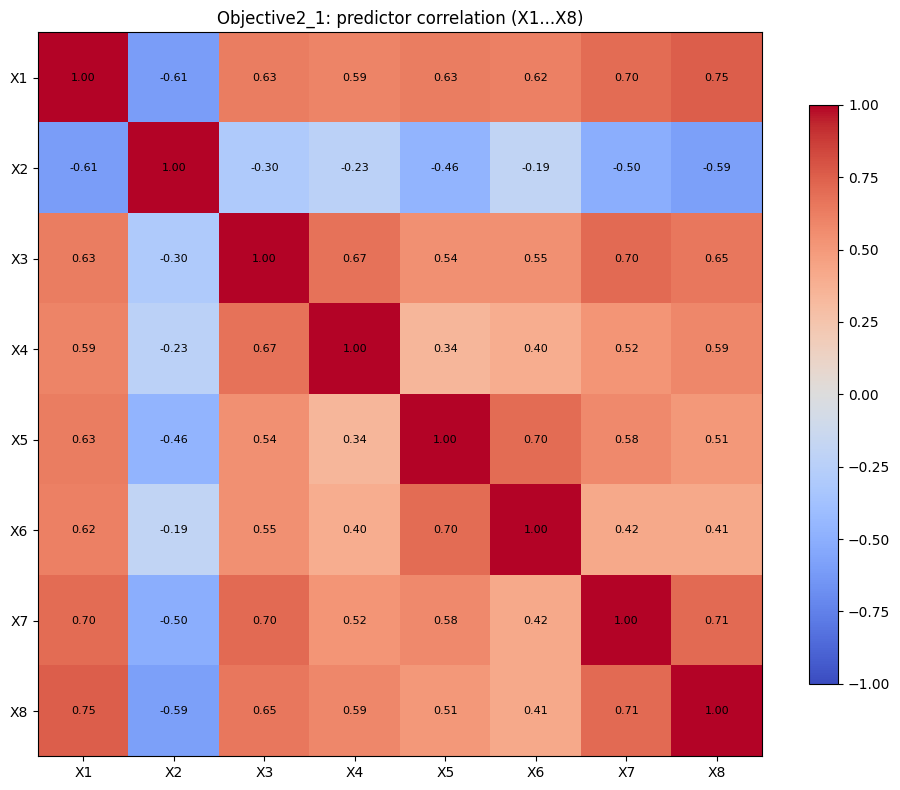

High-correlated feature pairs (|r|>=0.8): None


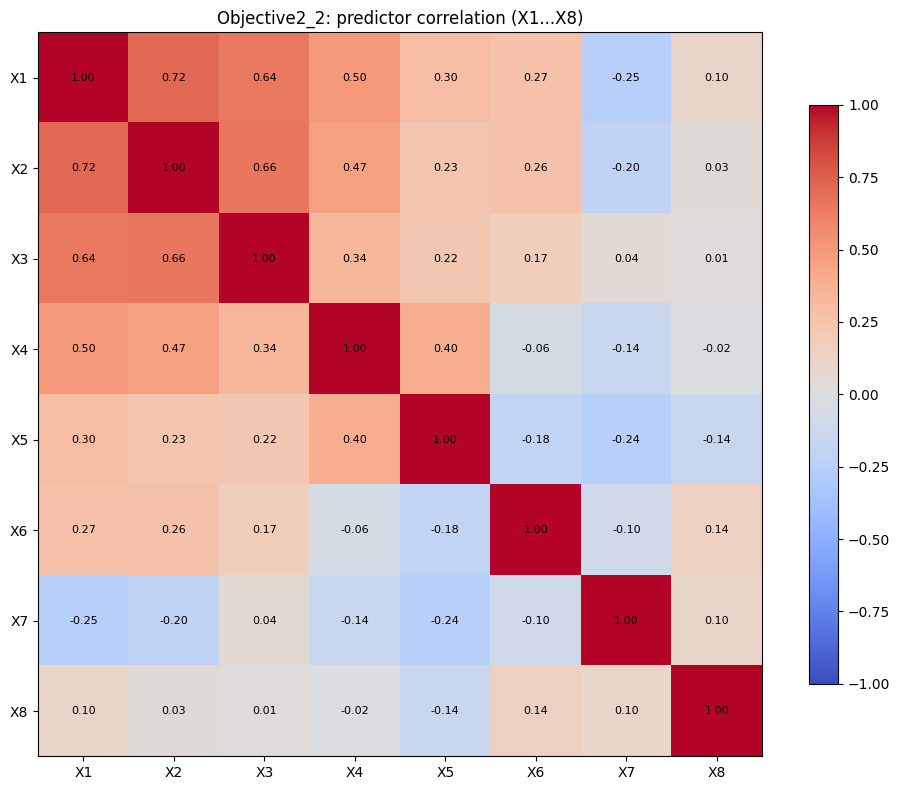

High-correlated feature pairs (|r|>=0.8): None


In [9]:
def plot_correlations(df, cols, label):
    mat=df[cols].corr()
    fig,ax=plt.subplots(figsize=(10,8))
    image=ax.imshow(mat.to_numpy(),cmap='coolwarm',vmin=-1,vmax=1)
    ax.set_xticks(range(len(cols)),[f'X{i}' for i in range(1,len(cols)+1)])
    ax.set_yticks(range(len(cols)),[f'X{i}' for i in range(1,len(cols)+1)])
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j,i,f'{mat.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
    ax.set_title(f'{label}: predictor correlation (X1...X8)')
    fig.colorbar(image,ax=ax,shrink=.8)
    plt.tight_layout()
    fig.savefig(OUT/f'{label}_Feature_Heatmap.png',dpi=160)
    plt.show()
    overlaps=[]
    for i in range(len(cols)):
        for j in range(i+1,len(cols)):
            r=mat.iloc[i,j]
            if pd.notna(r) and abs(r)>=.8: overlaps.append((cols[i],cols[j],round(r,3)))
    print('High-correlated feature pairs (|r|>=0.8):',overlaps if overlaps else 'None')

plot_correlations(f21,FEATURE21,'Objective2_1')
plot_correlations(f22,FEATURE22,'Objective2_2')

## 9. Train models with multiple splits — group-safe and reproducible

- For split sensitivity: random **60/40, 70/30, 80/20, 85/15** using **Match_ID groups** so both team records from one match always stay together.
- Main final assessment: **chronological 80/20** split by ordered matches. Training uses earlier fixtures; holdout consists of later ones.
- Models use exactly the **8 selected input columns**. Median imputation for opening-game history gaps and standardisation are learned **only on the training set**.
- We show both training and testing MAE, RMSE and R², plus a **training-mean baseline** for context.

**Interpretation:** Splits aren't tuned using the best test score; changing splits shows stability. The 80/20 chronological holdout remains the final evaluation even if another split looks better.

In [10]:
def split_match_groups(df,test_fraction=.2,mode='random',seed=SEED):
    ordered=df.sort_values(['Date','Match_ID'],kind='mergesort')
    match_ids=ordered['Match_ID'].drop_duplicates().to_numpy()
    if mode=='chronological':
        n_test=max(1,int(np.ceil(len(match_ids)*test_fraction)))
        train_ids=set(match_ids[:-n_test]); test_ids=set(match_ids[-n_test:])
    else:
        splitter=GroupShuffleSplit(n_splits=1,test_size=test_fraction,random_state=seed)
        train_idx,test_idx=next(splitter.split(ordered,groups=ordered.Match_ID))
        train_ids=set(ordered.iloc[train_idx].Match_ID)
        test_ids=set(ordered.iloc[test_idx].Match_ID)
    assert train_ids.isdisjoint(test_ids)
    train=ordered[ordered.Match_ID.isin(train_ids)].copy()
    test=ordered[ordered.Match_ID.isin(test_ids)].copy()
    assert len(train)>0 and len(test)>0
    return train,test

def fit_model(train, features, target):
    # Pipeline ensures no missing-value or scaling info is learned from test rows.
    model=Pipeline([
        ('median_impute',SimpleImputer(strategy='median')),
        ('scale',StandardScaler()),
        ('regression',LinearRegression()),
    ])
    model.fit(train[features],train[target])
    return model

def score_model(model,train,test,features,target,obj,split_name):
    yt=np.asarray(train[target],dtype=float)
    yh=np.asarray(test[target],dtype=float)
    p_train=model.predict(train[features]); p_test=model.predict(test[features])
    base=np.repeat(yt.mean(),len(yh))
    return dict(Objective=obj,Split=split_name,
                TrainMatches=train.Match_ID.nunique(),TestMatches=test.Match_ID.nunique(),
                TrainRows=len(train),TestRows=len(test),
                Train_MAE=mean_absolute_error(yt,p_train),
                Train_RMSE=np.sqrt(mean_squared_error(yt,p_train)),
                Train_R2=r2_score(yt,p_train),
                Test_MAE=mean_absolute_error(yh,p_test),
                Test_RMSE=np.sqrt(mean_squared_error(yh,p_test)),
                Test_R2=r2_score(yh,p_test),
                Baseline_Test_MAE=mean_absolute_error(yh,base),
                Baseline_Test_RMSE=np.sqrt(mean_squared_error(yh,base)))

def evaluate_splits(df,features,target,label):
    rows=[];models={}
    for fraction in [.40,.30,.20,.15]:
        train,test=split_match_groups(df,fraction,mode='random')
        model=fit_model(train,features,target)
        name=f'Random {int((1-fraction)*100)}/{int(fraction*100)}'
        rows.append(score_model(model,train,test,features,target,label,name))
        models[name]=(train,test,model)
    train,test=split_match_groups(df,.20,mode='chronological')
    model=fit_model(train,features,target)
    name='CHRONOLOGICAL 80/20 (final)'
    rows.append(score_model(model,train,test,features,target,label,name))
    models[name]=(train,test,model)
    table=pd.DataFrame(rows)
    display(table.round(3))
    return table,models

metrics21,models21=evaluate_splits(f21,FEATURE21,'Y_GoalDifference','Objective2_1')
metrics22,models22=evaluate_splits(f22,FEATURE22,'Y_TeamGoals','Objective2_2')
all_metrics=pd.concat([metrics21,metrics22],ignore_index=True)
# Individual CSV export consolidated in section 13.


,Objective,Split,TrainMatches,TestMatches,TrainRows,TestRows,Train_MAE,Train_RMSE,Train_R2,Test_MAE,Test_RMSE,Test_R2,Baseline_Test_MAE,Baseline_Test_RMSE
0,Objective2_1,Random 60/40,62,42,62,42,1.053,1.310,0.519,1.293,1.659,0.421,1.693,2.188
1,Objective2_1,Random 70/30,72,32,72,32,1.044,1.311,0.531,1.297,1.690,0.421,1.685,2.223
2,Objective2_1,Random 80/20,83,21,83,21,1.054,1.326,0.521,1.431,1.843,0.384,1.839,2.368
3,Objective2_1,Random 85/15,88,16,88,16,1.086,1.382,0.501,1.391,1.745,0.374,1.898,2.318
4,Objective2_1,CHRONOLOGICAL 80/20 (final),83,21,83,21,1.147,1.456,0.513,1.058,1.349,0.224,1.426,1.747


,Objective,Split,TrainMatches,TestMatches,TrainRows,TestRows,Train_MAE,Train_RMSE,Train_R2,Test_MAE,Test_RMSE,Test_R2,Baseline_Test_MAE,Baseline_Test_RMSE
0,Objective2_2,Random 60/40,62,42,124,84,0.925,1.208,0.261,0.924,1.159,0.280,1.107,1.367
1,Objective2_2,Random 70/30,72,32,144,64,0.892,1.171,0.273,0.936,1.196,0.296,1.137,1.425
2,Objective2_2,Random 80/20,83,21,166,42,0.882,1.163,0.279,0.954,1.202,0.327,1.214,1.468
3,Objective2_2,Random 85/15,88,16,176,32,0.887,1.176,0.279,0.984,1.148,0.320,1.259,1.418
4,Objective2_2,CHRONOLOGICAL 80/20 (final),83,21,166,42,0.886,1.147,0.337,0.932,1.258,0.083,1.045,1.315


## 10. Final 80/20 test predictions and residual visualisations

Use the chronological model as the **final** model. Each plot includes a 45° actual=predicted reference line. Scatter and residual patterns are inspected rather than assuming all assumptions hold just because a model was trained.

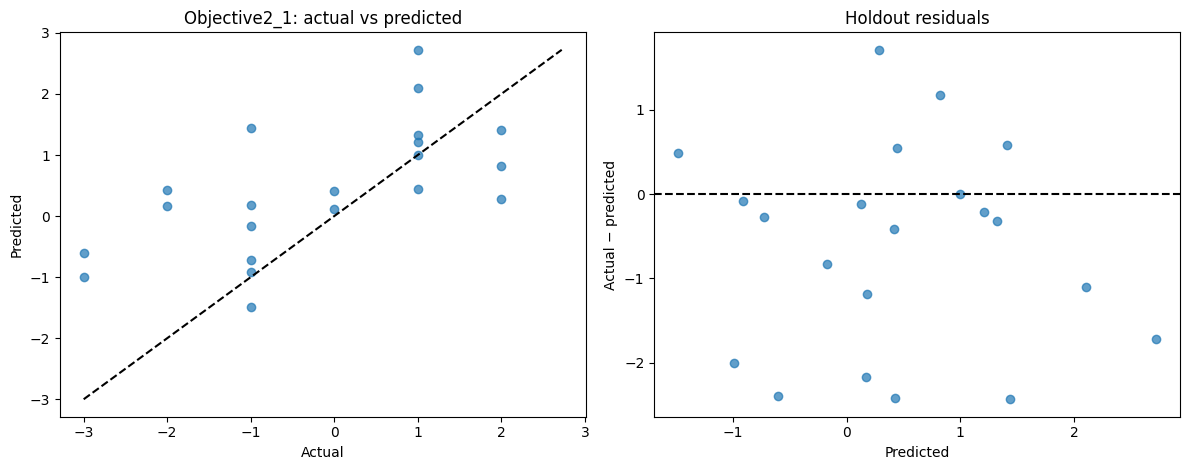

Final chronological test error summary: Objective2_1
count    21.00
mean     -0.63
std       1.22
min      -2.44
25%      -1.72
50%      -0.32
75%       0.00
max       1.71
Name: Residual, dtype: float64


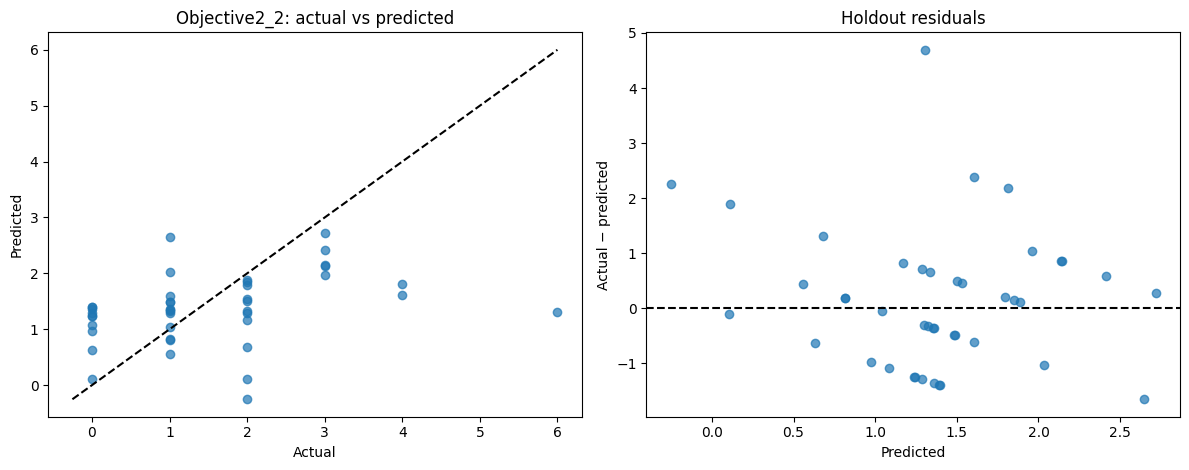

Final chronological test error summary: Objective2_2
count    42.00
mean      0.15
std       1.26
min      -1.65
25%      -0.62
50%       0.13
75%       0.70
max       4.69
Name: Residual, dtype: float64


In [11]:
def final_test_charts(model_pack,features,target,label):
    train,test,model=model_pack['CHRONOLOGICAL 80/20 (final)']
    pred=model.predict(test[features]); residuals=test[target].to_numpy()-pred
    actual=test[target].to_numpy()
    predictions=test[['Match_ID','Date']].copy()
    for c in (['Team_A','Team_B'] if 'Team_A' in test.columns else ['Team','Opponent']):
        predictions[c]=test[c].values
    predictions['Actual']=actual
    predictions['Predicted']=pred
    predictions['Residual']=residuals
    # Individual CSV export consolidated in section 13.
    fig,axes=plt.subplots(1,2,figsize=(12,4.8))
    axes[0].scatter(actual,pred,alpha=.7)
    low=min(actual.min(),pred.min()); high=max(actual.max(),pred.max())
    axes[0].plot([low,high],[low,high],'k--')
    axes[0].set(xlabel='Actual',ylabel='Predicted',title=f'{label}: actual vs predicted')
    axes[1].scatter(pred,residuals,alpha=.7)
    axes[1].axhline(0,color='black',linestyle='--')
    axes[1].set(xlabel='Predicted',ylabel='Actual − predicted',title='Holdout residuals')
    plt.tight_layout()
    fig.savefig(OUT/f'{label}_Final_Test_Diagnostics.png',dpi=160,bbox_inches='tight')
    plt.show()
    print('Final chronological test error summary:',label)
    print(pd.Series(residuals,name='Residual').describe().round(2))
    return predictions

pred21=final_test_charts(models21,FEATURE21,'Y_GoalDifference','Objective2_1')
pred22=final_test_charts(models22,FEATURE22,'Y_TeamGoals','Objective2_2')

## 11. OLS final diagnostics on the **training data only**

Because the assignment uses multiple linear regression, diagnostics include:

- Coefficients and their approximate p-values (conditional on model assumptions)
- **VIF** for correlated predictors (higher VIF = more collinearity)
- **Durbin–Watson** for residual serial correlation (mainly meaningful for chronologically ordered match rows)
- **Shapiro–Wilk** residual normality and **Breusch–Pagan** constant-variance test
- **Cook's distance** for potentially influential training observations
- Residual histogram and **Q–Q plot**

**Important:** The model's predictive performance is evaluated using the untouched **test** data. OLS inference below is about the model fit on its **training** data, not about test-set significance. For 2.2, two team-rows share a match and are not independent; **match-clustered standard errors** are used for the OLS coefficient table. The match-group split prevents train/test leakage.


========== Objective2_1 TRAINING OLS SUMMARY ==========
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.513
Model:                            OLS   Adj. R-squared:                  0.460
Method:                 Least Squares   F-statistic:                     9.728
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           4.07e-09
Time:                        15:18:35   Log-Likelihood:                -148.94
No. Observations:                  83   AIC:                             315.9
Df Residuals:                      74   BIC:                             337.6
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

,Variable,VIF
0,X1_Past7_WinRate_Diff,3.80
1,X2_Past7_GoalsConceded_Diff,2.22
2,X3_WC_Participations_Diff,3.25
3,X4_MostExpPlayer_Pre2026_Diff,2.24
4,X5_Prior_WC_GoalDifference_Diff,2.51
5,X6_Prior_WC_WinRate_Diff,2.30
6,X7_Log_MarketValue_Diff,3.01
7,X8_PreMatch_Computed_Elo_Diff,3.21


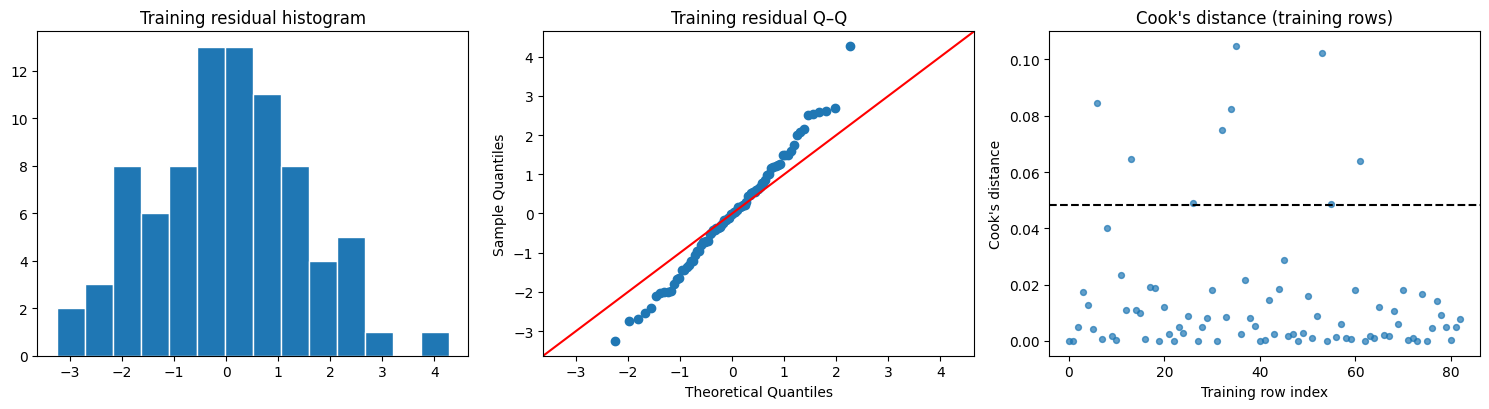


========== Objective2_2 TRAINING OLS SUMMARY ==========
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.337
Model:                            OLS   Adj. R-squared:                  0.303
Method:                 Least Squares   F-statistic:                     10.76
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           3.18e-10
Time:                        15:18:35   Log-Likelihood:                -258.29
No. Observations:                 166   AIC:                             534.6
Df Residuals:                     157   BIC:                             562.6
Df Model:                           8                                         
Covariance Type:              cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------

,Variable,VIF
0,X1_Log_MarketValue_Diff,2.72
1,X2_PreMatch_Computed_Elo_Diff,2.62
2,X3_Squad_Avg_WC_MatchesPP_Diff,2.26
3,X4_Past7_UnbeatenRate_Team,1.56
4,X5_Prior_WC_Team_AvgGoals,1.17
5,X6_Prior_WC_Opp_AvgConceded,1.15
6,X7_Avg_SquadAge_Team,1.25
7,X8_DaysSincePrevInternational_Team,1.07


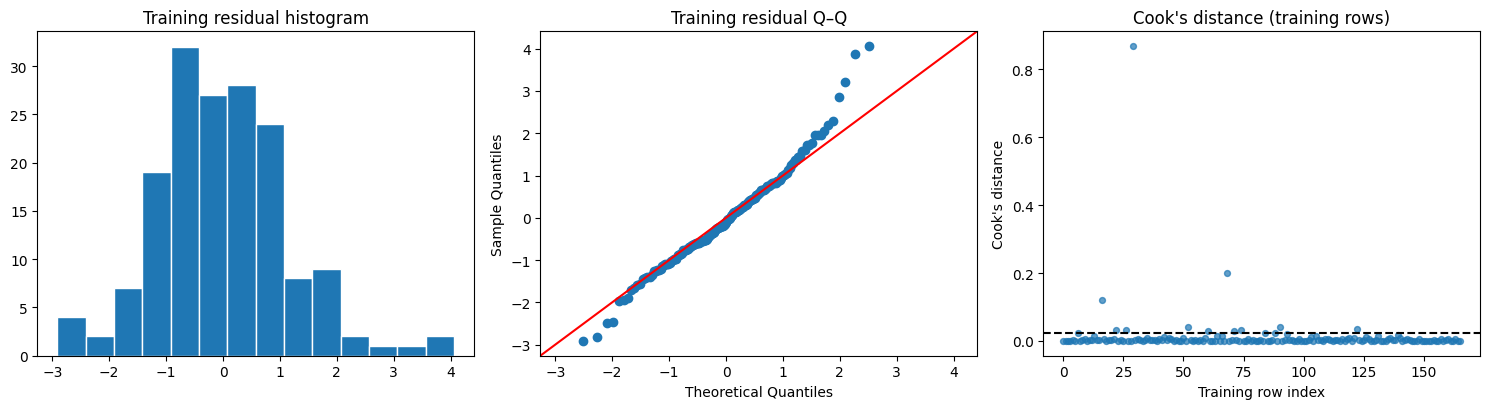

In [12]:
def regression_diagnostics(model_pack,features,target,label):
    train,test,model=model_pack['CHRONOLOGICAL 80/20 (final)']
    # Exact same training-time transformations as the sklearn regression.
    pre=model.named_steps['median_impute']
    scaler=model.named_steps['scale']
    x_train=scaler.transform(pre.transform(train[features]))
    x_design=sm.add_constant(x_train,has_constant='add')
    y=train[target].to_numpy(float)
    if label == 'Objective2_2':
        # Treat each match as a cluster because its two team rows share match shocks.
        ols=sm.OLS(y,x_design).fit(cov_type='cluster',cov_kwds={'groups':train['Match_ID'].to_numpy()})
    else:
        ols=sm.OLS(y,x_design).fit()
    print('\n==========',label,'TRAINING OLS SUMMARY ==========')
    print(ols.summary())
    try:
        vif=pd.DataFrame({'Variable':features,
                          'VIF':[variance_inflation_factor(x_train,i) for i in range(len(features))]})
    except Exception as e:
        print('VIF warning:',str(e)); vif=pd.DataFrame({'Variable':features,'VIF':np.nan})
    # Individual CSV export consolidated in section 13.
    print('\nVariance inflation factors:'); display(vif.round(2))
    residuals=np.asarray(ols.resid)
    cooks=np.asarray(ols.get_influence().cooks_distance[0])
    shapiro=stats.shapiro(residuals)
    try:
        bp=het_breuschpagan(residuals,x_design)
        bp_p=bp[1]
    except Exception:
        bp_p=np.nan
    tests=pd.DataFrame([{
        'Objective':label,'Training_Observations':len(train),
        'Training_Adjusted_R2':ols.rsquared_adj,
        'Residual_Shapiro_P':shapiro.pvalue,
        'Breusch_Pagan_P':bp_p,
        'Durbin_Watson':durbin_watson(residuals),
        'Influential_Train_Rows_CooksGt4N':(cooks>4/len(train)).sum(),
        'Max_Cooks_Distance':cooks.max(),
        'Matrix_Rank':np.linalg.matrix_rank(x_design),
    }])
    # Individual CSV export consolidated in section 13.
    fig,axs=plt.subplots(1,3,figsize=(15,4.2))
    axs[0].hist(residuals,bins=14,edgecolor='white')
    axs[0].set_title('Training residual histogram')
    sm.qqplot(residuals,line='45',ax=axs[1]); axs[1].set_title('Training residual Q–Q')
    axs[2].scatter(np.arange(len(cooks)),cooks,s=18,alpha=.7)
    axs[2].axhline(4/len(train),color='black',linestyle='--')
    axs[2].set_title("Cook's distance (training rows)")
    axs[2].set(xlabel='Training row index',ylabel="Cook's distance")
    plt.tight_layout()
    fig.savefig(OUT/f'{label}_OLS_Assumption_Diagnostics.png',dpi=160,bbox_inches='tight')
    plt.show()
    return ols,tests,vif

ols21,tests21,vif21=regression_diagnostics(models21,FEATURE21,'Y_GoalDifference','Objective2_1')
ols22,tests22,vif22=regression_diagnostics(models22,FEATURE22,'Y_TeamGoals','Objective2_2')

## 12. Final interpretation and submission checklist

1. Confirm final **104** rows for 2.1 and **208** team rows for 2.2, with exactly **eight original explanatory variables per model**.
2. Explain **cold-start missingness**: prior-2026-tournament form is unavailable for opening matches, so median imputation is fit on the training rows only. Mention the first-match limitation.
3. Discuss Pearson `r`, scatterplot shape, high-correlation pairs and VIF; two 2.1 win-rate predictors may be redundant.
4. Compare MAE/RMSE/R² across splits. Use the **chronological 80/20** as the final estimate rather than choosing the split with the most favourable test R².
5. Discuss actual-vs-predicted plot, residual histogram, Q–Q plot, Breusch–Pagan, Durbin–Watson and Cook's distance. R² may be **negative** on new data; report it rather than hiding it.
6. **Required before submission:** Replace 2.2 X3 with **verified pre-2026 squad World Cup matches per player** and document the collection method. The `Experience.csv` value is post-tournament and therefore may leak results. Verify that market-value snapshots were known before matches. If the instructor expects *official* Elo, replace the internally computed series with timestamped official pre-match ratings.
7. Use match-aware validation: both team rows from each match must be in the same train or test set (done here). Since goals are nonnegative counts, linear regression may predict a negative number; mention this modelling limitation.

**All three regenerated analysis/results CSVs are saved into `CSV_Files/`; plots and figures are saved in `plots/`.** Models are for coursework analysis, not betting or operational forecasts.

In [13]:
print('Objective 2.1 input data:',len(f21),'rows; 8 predictors:',len(FEATURE21))
print('Objective 2.2 input data:',len(f22),'rows; 8 predictors:',len(FEATURE22))
print('2.1 final chronological split:')
display(metrics21.tail(1)[['TrainMatches','TestMatches','Test_MAE','Test_RMSE','Test_R2','Baseline_Test_MAE']].round(3))
print('2.2 final chronological split:')
display(metrics22.tail(1)[['TrainMatches','TestMatches','Test_MAE','Test_RMSE','Test_R2','Baseline_Test_MAE']].round(3))
print('Verified PRE-2026 squad experience in Objective 2.2:',verified_pre2026_experience)
print('2.1 previous-form missing rows:',f21[FEATURE21].isna().any(axis=1).sum())
print('2.2 previous-form missing rows:',f22[FEATURE22].isna().any(axis=1).sum())
print('Generated outputs will be finalised in Section 13.')
for path in sorted(OUT.glob('*')):
    print(' -',path.name)
if not verified_pre2026_experience:
    display(Markdown('### ⚠️ Objective 2.2 is EXPLORATORY, not final submission-ready. '
                     'A verified pre-2026 squad-experience source is still required.'))

Objective 2.1 input data: 104 rows; 8 predictors: 8
Objective 2.2 input data: 208 rows; 8 predictors: 8
2.1 final chronological split:


,TrainMatches,TestMatches,Test_MAE,Test_RMSE,Test_R2,Baseline_Test_MAE
4,83,21,1.058,1.349,0.224,1.426


2.2 final chronological split:


,TrainMatches,TestMatches,Test_MAE,Test_RMSE,Test_R2,Baseline_Test_MAE
4,83,21,0.932,1.258,0.083,1.045


Verified PRE-2026 squad experience in Objective 2.2: False
2.1 previous-form missing rows: 24
2.2 previous-form missing rows: 48
Generated outputs will be finalised in Section 13.
 - Objective2_1_Eight_Scatterplots.png
 - Objective2_1_Feature_Heatmap.png
 - Objective2_1_Final_Test_Diagnostics.png
 - Objective2_1_OLS_Assumption_Diagnostics.png
 - Objective2_2_Eight_Scatterplots.png
 - Objective2_2_Feature_Heatmap.png
 - Objective2_2_Final_Test_Diagnostics.png
 - Objective2_2_OLS_Assumption_Diagnostics.png


### ⚠️ Objective 2.2 is EXPLORATORY, not final submission-ready. A verified pre-2026 squad-experience source is still required.

## 13. Three standardised, **renamed** CSV outputs

The notebook writes exactly three regenerated analysis/result CSVs into the **same `CSV_Files/` folder** as the six retained and three consolidated source CSVs. Models use the current recomputed data; a test split indicator and final holdout predictions appear alongside each dataset. Evaluation metrics and diagnostic statistics are in a long/tidy results table.


In [14]:
# Export THREE standardised CSVs (two analysis datasets + one tidy results table).
# Original source CSVs are read from CSV_Files/; only the three named outputs are overwritten.



def join_test_predictions(frame, predictions, keys):
    test_predictions = predictions[keys + ['Predicted', 'Residual']].copy()
    test_predictions = test_predictions.rename(columns={
        'Predicted': 'Final_Test_Predicted',
        'Residual': 'Final_Test_Residual',
    })
    data = frame.merge(test_predictions, on=keys, how='left', validate='one_to_one', sort=False)
    test_keys = set(map(tuple, predictions[keys].itertuples(index=False, name=None)))
    data['Final_Chronological_Split'] = [
        'Test' if key in test_keys else 'Train'
        for key in map(tuple, data[keys].itertuples(index=False, name=None))
    ]
    assert (data['Final_Chronological_Split'] == 'Test').sum() == len(predictions)
    return data

final21 = join_test_predictions(f21, pred21, ['Match_ID'])
final22 = join_test_predictions(f22, pred22, ['Match_ID', 'Team'])

extra_columns = ['Final_Chronological_Split', 'Final_Test_Predicted', 'Final_Test_Residual']
cols21 = ['Match_ID', 'Date', 'Round', 'Team_A', 'Team_B'] + FEATURE21 + ['Y_GoalDifference'] + extra_columns
cols22 = ['TeamMatch_ID', 'Match_ID', 'Date', 'Round', 'Team', 'Opponent'] + FEATURE22 + ['Y_TeamGoals'] + extra_columns
assert len(final21) == 104 and len(FEATURE21) == 8
assert len(final22) == 208 and len(FEATURE22) == 8
assert final21['Match_ID'].is_unique
assert not final22.duplicated(['Match_ID', 'Team']).any()
assert final22.groupby('Match_ID').size().eq(2).all()

final21[cols21].to_csv(DATA_DIR / OUTPUT_21, index=False)
final22[cols22].to_csv(DATA_DIR / OUTPUT_22, index=False)

# A tidy/long table avoids 7 separate result files with incompatible columns.
# Each record is a single numeric result, with split/objective/metric explicitly labelled.
results = []
def add_result(objective, kind, split, variable, metric, value, origin):
    if pd.isna(value):
        return
    units = {
        'TrainMatches':'matches', 'TestMatches':'matches',
        'TrainRows':'rows', 'TestRows':'rows',
        'Train_MAE':'goals', 'Train_RMSE':'goals', 'Train_R2':'score',
        'Test_MAE':'goals', 'Test_RMSE':'goals', 'Test_R2':'score',
        'Baseline_Test_MAE':'goals', 'Baseline_Test_RMSE':'goals',
        'Training_Observations':'rows', 'Training_Adjusted_R2':'score',
        'Residual_Shapiro_P':'p-value', 'Breusch_Pagan_P':'p-value',
        'Durbin_Watson':'statistic', 'Influential_Train_Rows_CooksGt4N':'rows',
        'Max_Cooks_Distance':'statistic', 'Matrix_Rank':'count', 'VIF':'VIF',
    }
    results.append(dict(Objective=objective,Result_Type=kind,Split=split,
                        Variable=variable,Metric=metric,Value=value,
                        Unit=units.get(metric,'number'),Original_Output_File=origin))

for _, r in all_metrics.iterrows():
    for metric in all_metrics.columns:
        if metric not in ('Objective','Split'):
            add_result(r.Objective,'Split metric',r.Split,'',metric,r[metric],'All_Split_Metrics.csv')

for objective, diagnostics, vif in [
    ('Objective2_1', tests21, vif21),
    ('Objective2_2', tests22, vif22),
]:
    for metric in diagnostics.columns:
        if metric != 'Objective':
            add_result(objective, 'Training diagnostic', 'CHRONOLOGICAL 80/20 (final)',
                       '', metric, diagnostics.iloc[0][metric], f'{objective}_Train_Diagnostic_Tests.csv')
    for _, row in vif.iterrows():
        add_result(objective,'VIF','CHRONOLOGICAL 80/20 (final)',
                   row.Variable, 'VIF', row.VIF, f'{objective}_VIF.csv')

final_results = pd.DataFrame(results, columns=[
    'Objective','Result_Type','Split','Variable','Metric','Value','Unit','Original_Output_File'
])
assert len(final_results) == 152, len(final_results)
final_results.to_csv(DATA_DIR / OUTPUT_METRICS,index=False)

print('Exactly three consolidated CSV output files:')
for f in [DATA_DIR / OUTPUT_21, DATA_DIR / OUTPUT_22, DATA_DIR / OUTPUT_METRICS]:
    print('  ', f.name, '—', len(pd.read_csv(f)), 'rows')
print('All source CSVs are in CSV_Files/. No original ZIP archives are required.')


Exactly three consolidated CSV output files:
   FIFA2026_Objective2_1_Goal_Difference_104_Matches.csv — 104 rows
   FIFA2026_Objective2_2_Goals_Scored_208_TeamMatches.csv — 208 rows
   FIFA2026_Objective2_Model_Evaluation_and_Diagnostics.csv — 152 rows
All source CSVs are in CSV_Files/. No original ZIP archives are required.
